# Milestone 2 — Feature Engineering & Imbalance Handling (corrected)

**Task:** Compare class weighting with SMOTE (SMOTE on training data only). Train and tune random forest and gradient boosting
on the same split, and pick the best one using **validation** results. **Do not touch the test set yet.**

**How the years are used in this notebook**

| Year | Role | What we do with it |
|---|---|---|
| 1994 | **Fit** | Models learn from it. SMOTE is only ever applied here. |
| 1995 | **Validation** | We grade every choice (features, imbalance method, model, settings) here. |
| 1996 | **Hold-out test** | Locked. Counted once, never cleaned, encoded, or scored. Opened once, after the team agrees on a final model. |

Every step ends with `check(...)` lines. If anything is wrong, the notebook stops with a red error instead of quietly giving bad numbers.

## Step 0 — Imports and a tiny helper for checks

In [1]:
import json, time, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score
from imblearn.over_sampling import SMOTENC   # pip install imbalanced-learn

pd.set_option('display.max_columns', None)

# One number used everywhere randomness appears, so re-running gives the SAME results.
RANDOM_STATE = 42

def check(condition, message):
    # A "check" is a promise about the data. If the promise is broken, stop right away.
    # This is better than finding a silent bug after the numbers are already in a slide.
    if not condition:
        raise AssertionError('CHECK FAILED: ' + message)
    print('  ✓', message)

## Step 1 — Load the data

In [2]:
# Try the team repo's path first, then the same folder as this notebook.
for path in ['../data/fraud_oracle.csv', 'fraud_oracle.csv']:
    try:
        df = pd.read_csv(path)
        print('Loaded', path)
        break
    except FileNotFoundError:
        continue

print('Rows and columns:', df.shape)
check(df.shape == (15420, 33), 'dataset has 15,420 claims and 33 columns')
check(set(df['FraudFound_P'].unique()) == {0, 1}, 'label is 0 (not fraud) or 1 (fraud)')
check(set(df['Year'].unique()) == {1994, 1995, 1996}, 'years are exactly 1994, 1995, 1996')
check(df.isna().sum().sum() == 0, 'no blank cells (Age = 0 is the hidden "missing" value)')

Loaded fraud_oracle.csv
Rows and columns: (15420, 33)
  ✓ dataset has 15,420 claims and 33 columns
  ✓ label is 0 (not fraud) or 1 (fraud)
  ✓ years are exactly 1994, 1995, 1996
  ✓ no blank cells (Age = 0 is the hidden "missing" value)


## Step 2 — Lock away 1996 FIRST

**What went wrong before:** copy 2 and copy 3 both ran the model on 1996 (the confusion matrix, the "Tuned GB vs Baseline LR" table,
and the 38.8% flag-rate comparison). Every time you look at test results and then make a choice, the test set stops being a fair final exam.

Here we split 1996 off before doing anything else and take a *fingerprint* of it. At the very end we confirm the fingerprint never changed
and that no 1996 row ever went into a model.

In [3]:
dev_df = df[df['Year'].isin([1994, 1995])].copy()      # "development" data: everything we're allowed to use
holdout_1996 = df[df['Year'] == 1996].copy()           # LOCKED. Only counted below, nothing else.

# A fingerprint is one number computed from every cell in the table.
# If even one value changes later, the fingerprint changes.
HOLDOUT_FINGERPRINT = int(pd.util.hash_pandas_object(holdout_1996, index=True).sum())

print(f'Development (1994-95): {len(dev_df):,} claims')
print(f'Hold-out 1996 (locked): {len(holdout_1996):,} claims  <- we will NOT look at its fraud rate or score it')

check(len(dev_df) + len(holdout_1996) == len(df), 'every claim is in exactly one group')
check(set(dev_df.index).isdisjoint(holdout_1996.index), 'no claim is in both groups')

Development (1994-95): 11,337 claims
Hold-out 1996 (locked): 4,083 claims  <- we will NOT look at its fraud rate or score it
  ✓ every claim is in exactly one group
  ✓ no claim is in both groups


## Step 3 — Split development data: fit on 1994, validate on 1995

This is a *temporal* split, the same idea as the September split (past → future), just one level inside the training years.
The model learns from 1994 and is graded on 1995, which plays the role of "the future" while we tune.

In [4]:
fit_raw = dev_df[dev_df['Year'] == 1994].copy()   # the model studies this
val_raw = dev_df[dev_df['Year'] == 1995].copy()   # the "practice test" we grade every choice on

summary = pd.DataFrame({
    'Role': ['Fit (1994)', 'Validation (1995)'],
    'Claims': [len(fit_raw), len(val_raw)],
    'Fraud cases': [fit_raw['FraudFound_P'].sum(), val_raw['FraudFound_P'].sum()],
    'Fraud rate': [fit_raw['FraudFound_P'].mean(), val_raw['FraudFound_P'].mean()],
})
display(summary.round(4))

check(len(fit_raw) + len(val_raw) == len(dev_df), 'fit + validation = all of 1994-95')
check(set(fit_raw.index).isdisjoint(val_raw.index), 'fit and validation do not share claims')
check(val_raw['FraudFound_P'].sum() >= 100, 'validation has 100+ fraud cases (enough to compare models, but still noisy)')

,Role,Claims,Fraud cases,Fraud rate
0,Fit (1994),6142,409,0.0666
1,Validation (1995),5195,301,0.0579


  ✓ fit + validation = all of 1994-95
  ✓ fit and validation do not share claims
  ✓ validation has 100+ fraud cases (enough to compare models, but still noisy)


## Step 4 — Choose columns (same leakage decisions as before)

These are the same drops from the September audit. Leaving them unchanged keeps this milestone comparable to the baseline.

In [5]:
drop_reasons = {
    'Fault': 'Fault might be decided after an investigation.',
    'PolicyNumber': 'An ID number that also closely follows the year.',
    'RepNumber': 'An employee ID; we do not know when they were assigned.',
    'AgeOfPolicyHolder': 'The youngest age group appears only when Age is 0.',
    'PoliceReportFiled': 'The police report might be filed later.',
    'WitnessPresent': 'Witnesses might be found during the investigation.',
    'NumberOfSuppliments': 'More supplements could be added after filing.',
    'AddressChange_Claim': 'We need to confirm what this column means.',
    'Year': 'Used for the split, not as a model input.',
}
LABEL = 'FraudFound_P'
base_columns = [c for c in df.columns if c not in drop_reasons and c != LABEL]

# Columns whose values are labels, not amounts. They get one-hot encoded.
# (WeekOfMonth "3" isn't "three times bigger" than week 1, so we treat it as a label.)
category_columns = [c for c in base_columns if df[c].dtype == object or str(df[c].dtype) in ('str', 'string')]
category_columns += ['WeekOfMonth', 'WeekOfMonthClaimed', 'DriverRating']

print(len(base_columns), 'base columns |', len(category_columns), 'of them are categories')
check(LABEL not in base_columns, 'the answer column is not used as an input')
check(not set(drop_reasons) & set(base_columns), 'none of the dropped (possible leakage) columns slipped back in')
check(set(category_columns) <= set(base_columns), 'every category column is a real input column')

23 base columns | 21 of them are categories
  ✓ the answer column is not used as an input
  ✓ none of the dropped (possible leakage) columns slipped back in
  ✓ every category column is a real input column


## Step 5 — Feature engineering (new this milestone)

Neither earlier notebook did any feature engineering, but it is part of the milestone. We add a few features that use **only information
on the claim form**, and each one is computed from a single row (no averages over other claims), so it can't leak information between years.

* **Ordered versions of range columns.** `VehiclePrice` "less than 20000" < "20000 to 29000" < ... has a real order. One-hot encoding throws that order away,
  so we add a number version (0, 1, 2, ...) that trees can split on ("price ≥ level 3").
* **ClaimDelayWeeks** — roughly how many weeks passed between the accident and the claim. Long delays are a classic fraud signal.
* **ClaimedOnWeekend** — claims are almost always filed Mon–Fri, so a weekend filing is unusual.

We keep these only if they clearly help on 1995 (Step 9 tests that). Trying a feature and dropping it is a valid, reportable result.

In [6]:
# Maps from text ranges to ordered numbers. Lower number = smaller / fewer / newer.
ORDINAL_MAPS = {
    'VehiclePrice': {'less than 20000': 0, '20000 to 29000': 1, '30000 to 39000': 2,
                     '40000 to 59000': 3, '60000 to 69000': 4, 'more than 69000': 5},
    'AgeOfVehicle': {'new': 0, '2 years': 2, '3 years': 3, '4 years': 4, '5 years': 5,
                     '6 years': 6, '7 years': 7, 'more than 7': 8},
    'Days_Policy_Accident': {'none': 0, '1 to 7': 1, '8 to 15': 2, '15 to 30': 3, 'more than 30': 4},
    'Days_Policy_Claim': {'none': 0, '8 to 15': 1, '15 to 30': 2, 'more than 30': 3},
    'PastNumberOfClaims': {'none': 0, '1': 1, '2 to 4': 2, 'more than 4': 3},
    'NumberOfCars': {'1 vehicle': 1, '2 vehicles': 2, '3 to 4': 3, '5 to 8': 4, 'more than 8': 5},
}
MONTH_NUM = {m: i for i, m in enumerate(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])}
ENGINEERED = [c + '_ord' for c in ORDINAL_MAPS] + ['ClaimDelayWeeks', 'ClaimedOnWeekend']

def add_features(d):
    d = d.copy()
    for col, mapping in ORDINAL_MAPS.items():
        d[col + '_ord'] = d[col].map(mapping)            # any value not in the map becomes NaN (we check for that)

    # Weeks between accident and claim:
    #   months apart (wrapping Dec -> Jan with % 12) * ~4.3 weeks, plus the difference in week-of-month.
    acc_month = d['Month'].map(MONTH_NUM)
    claim_month = d['MonthClaimed'].map(MONTH_NUM)       # 'Unknown' -> NaN
    months_apart = (claim_month - acc_month) % 12
    delay = months_apart * 4.3 + (d['WeekOfMonthClaimed'] - d['WeekOfMonth'])
    d['ClaimDelayWeeks'] = delay.clip(lower=0).fillna(0).round(1)   # unknown claim month (1 row) -> 0

    d['ClaimedOnWeekend'] = d['DayOfWeekClaimed'].isin(['Saturday', 'Sunday']).astype(int)
    return d

# --- Checks on the 1994 data only (we don't need to peek at anything else to test the function) ---
tmp = add_features(fit_raw)
check(tmp[ENGINEERED].isna().sum().sum() == 0, 'every range value got an ordered number (no typos in the maps)')
check(tmp['ClaimDelayWeeks'].between(0, 60).all(), 'claim delay is between 0 and 60 weeks')
check(len(tmp) == len(fit_raw), 'adding features did not add or drop any rows')
print('\nTypical claim delay (weeks):')
print(tmp['ClaimDelayWeeks'].describe().round(1).to_string())

  ✓ every range value got an ordered number (no typos in the maps)
  ✓ claim delay is between 0 and 60 weeks
  ✓ adding features did not add or drop any rows

Typical claim delay (weeks):
count    6142.0
mean        1.5
std         3.6
min         0.0
25%         0.0
50%         1.0
75%         1.3
max        51.3


## Step 6 — Cleaning and encoding functions

Same cleaning as the baseline, written as reusable functions so every model gets identical treatment.

**Golden rule:** anything *learned* from data (the age median, the list of one-hot columns, the scaler's mean/std) is learned from the **fit year only**,
then reused as-is on validation. Otherwise 1995 information leaks into training.

In [7]:
def clean(d, age_median):
    # Age = 0 really means "missing". Keep a flag so the model can still use "age was missing" as a clue.
    d = d.copy()
    d['AgeMissing'] = (d['Age'] == 0).astype(int)
    d['Age'] = d['Age'].replace(0, np.nan).fillna(age_median)
    for c in ['MonthClaimed', 'DayOfWeekClaimed']:
        d[c] = d[c].astype(str).replace('0', 'Unknown')   # one claim has '0' here
    return d

def encode(train_d, other_ds, use_fe):
    # Turn text categories into 0/1 columns. The column list comes from the TRAINING data only;
    # other data is forced into the same columns (missing ones filled with 0, unseen ones dropped).
    inputs = base_columns + ['AgeMissing'] + (ENGINEERED if use_fe else [])
    X_train = pd.get_dummies(train_d[inputs], columns=category_columns, dtype=int)
    X_others = [pd.get_dummies(o[inputs], columns=category_columns, dtype=int)
                  .reindex(columns=X_train.columns, fill_value=0) for o in other_ds]
    return X_train, X_others

# Age median learned from 1994 only
AGE_MEDIAN = fit_raw.loc[fit_raw['Age'] > 0, 'Age'].median()
fit_clean = clean(fit_raw, AGE_MEDIAN)
val_clean = clean(val_raw, AGE_MEDIAN)
y_fit = fit_clean[LABEL].to_numpy()
y_val = val_clean[LABEL].to_numpy()

print('Age median from 1994:', AGE_MEDIAN)
check((fit_clean['Age'] > 0).all() and (val_clean['Age'] > 0).all(), 'no Age = 0 left after cleaning')
check(fit_clean['AgeMissing'].sum() == (fit_raw['Age'] == 0).sum(), 'AgeMissing flag matches the number of Age = 0 rows')

Age median from 1994: 38.0
  ✓ no Age = 0 left after cleaning
  ✓ AgeMissing flag matches the number of Age = 0 rows


## Step 7 — How we grade models (decided BEFORE looking at any results)

* **Primary metric: Average Precision (AP).** It scores how well the model *ranks* claims (fraud near the top). It doesn't depend on picking a threshold,
  which is good because the business hasn't told us how many claims investigators can review. A model that guesses randomly gets AP ≈ the fraud rate (≈ 0.058 on 1995).
* **Secondary: recall and lift in the top 10%.** "If investigators review the 10% riskiest claims, what share of all fraud do they catch, and how many
  times better is that than picking claims at random?"

We pick the winner by AP. **Tie-break:** if the top two are within noise (the leader stays ahead in fewer than 75% of bootstrap resamples, Step 13),
we choose the one with higher recall@10%, because that's what investigators actually feel. Deciding the rule first stops us from choosing whichever metric happens to make our favorite model look best.

In [8]:
def top_k_stats(y, probs, frac=0.10):
    k = int(len(probs) * frac)                         # how many claims get reviewed
    top = np.argsort(-probs)[:k]                       # positions of the k highest scores
    caught = y[top].sum()                              # fraud cases inside the reviewed pile
    recall = caught / y.sum()                          # share of ALL fraud we caught
    lift = (caught / k) / y.mean()                     # how much better than random reviewing
    return recall, lift

def grade(y, probs):
    recall10, lift10 = top_k_stats(y, probs)
    return {'AP': average_precision_score(y, probs), 'recall@10%': recall10, 'lift@10%': lift10}

# Sanity check the grader itself on fake scores:
rng = np.random.default_rng(RANDOM_STATE)
perfect = grade(y_val, y_val + rng.random(len(y_val)) * 0.1)    # fraud always scores higher
random_ = grade(y_val, rng.random(len(y_val)))                  # pure coin flips
check(perfect['AP'] > 0.99, 'a perfect ranking gets AP ≈ 1')
check(abs(random_['AP'] - y_val.mean()) < 0.02, f"random scores get AP ≈ fraud rate ({y_val.mean():.3f})")

  ✓ a perfect ranking gets AP ≈ 1
  ✓ random scores get AP ≈ fraud rate (0.058)


## Step 8 — SMOTE done correctly (training year only)

**SMOTE** makes fake fraud cases by taking a real fraud claim, finding a similar fraud claim, and creating a new claim "in between" them.
Plain SMOTE averages numbers, which breaks categories (you can't be halfway between Honda and Toyota). **SMOTENC** averages only the true numbers and
copies a real category from a neighbor for everything else.

Rules we follow:
1. Resample **1994 only.** Validation stays 100% real claims, otherwise we'd be grading on fake data.
2. Resample **before** one-hot encoding (so SMOTENC sees whole categories), and compute engineered features **after** (so they always agree with the columns they come from).
3. Treat `Deductible` as a category. It only has 4 real values (300/400/500/700). **Copy 2 treated it as a number, so SMOTENC invented deductibles like 437 that don't exist.**

In [9]:
SMOTE_COLUMNS = base_columns + ['AgeMissing']
# Everything except Age is treated as a category by SMOTENC (Deductible + AgeMissing included on purpose).
smote_cat_cols = [c for c in SMOTE_COLUMNS if c != 'Age']
smote_cat_idx = [SMOTE_COLUMNS.index(c) for c in smote_cat_cols]

def smote_fit_year(fit_clean_df):
    X = fit_clean_df[SMOTE_COLUMNS].copy()
    for c in smote_cat_cols:
        X[c] = X[c].astype(str)                        # SMOTENC compares categories as text labels
    sm = SMOTENC(categorical_features=smote_cat_idx, random_state=RANDOM_STATE)
    X_res, y_res = sm.fit_resample(X, fit_clean_df[LABEL])
    # Turn number-like columns back into numbers
    for c in ['WeekOfMonth', 'WeekOfMonthClaimed', 'DriverRating', 'Deductible', 'AgeMissing']:
        X_res[c] = X_res[c].astype(int)
    X_res[LABEL] = y_res.to_numpy()
    return X_res

fit_smote = smote_fit_year(fit_clean)
n_real = len(fit_clean)
synthetic = fit_smote.iloc[n_real:]

print('Before SMOTE:', pd.Series(y_fit).value_counts().to_dict())
print('After  SMOTE:', fit_smote[LABEL].value_counts().to_dict())
check(fit_smote[LABEL].value_counts().nunique() == 1, 'classes are balanced 50/50 after SMOTE')
check((fit_smote.iloc[:n_real][SMOTE_COLUMNS].astype(str).values ==
       fit_clean[SMOTE_COLUMNS].astype(str).values).all(), 'the original 1994 rows are untouched (SMOTE only ADDS rows)')
check((synthetic[LABEL] == 1).all(), 'every synthetic row is a fraud case')
check(set(synthetic['Deductible']) <= set(fit_clean['Deductible']), 'synthetic deductibles are real values only (300/400/500/700)')
for c in category_columns:
    if not set(synthetic[c].astype(str)) <= set(fit_clean[c].astype(str)):
        raise AssertionError(f'CHECK FAILED: invented category in {c}')
print('  ✓ every synthetic category value already exists in real 1994 claims')
check(synthetic['Age'].between(fit_clean['Age'].min(), fit_clean['Age'].max()).all(), 'synthetic ages stay inside the real age range')
check(len(val_clean) == len(val_raw), 'validation was NOT resampled (same size as before)')

Before SMOTE: {0: 5733, 1: 409}
After  SMOTE: {0: 5733, 1: 5733}
  ✓ classes are balanced 50/50 after SMOTE
  ✓ the original 1994 rows are untouched (SMOTE only ADDS rows)
  ✓ every synthetic row is a fraud case
  ✓ synthetic deductibles are real values only (300/400/500/700)
  ✓ every synthetic category value already exists in real 1994 claims
  ✓ synthetic ages stay inside the real age range
  ✓ validation was NOT resampled (same size as before)


## Step 9 — Build the model-ready tables, then test whether feature engineering helps

We make the 0/1 tables for every combination we need. The SMOTE table is forced into the **same columns** as the normal 1994 table so all models see identical inputs.

Then a quick, fair test of feature engineering: same model (gradient boosting with class weights, default-ish settings), same data, only difference = with/without the new features.

In [10]:
def build_tables(use_fe):
    f = add_features(fit_clean) if use_fe else fit_clean
    v = add_features(val_clean) if use_fe else val_clean
    s = add_features(fit_smote) if use_fe else fit_smote
    X_fit, (X_val, X_smote) = encode(f, [v, s], use_fe)

    # Scale the true-number columns using 1994 stats only. (Trees don't need this, logistic regression does.)
    num_cols = ['Age', 'Deductible'] + (ENGINEERED if use_fe else [])
    scaler = StandardScaler().fit(X_fit[num_cols])
    for X in (X_fit, X_val, X_smote):
        X[num_cols] = scaler.transform(X[num_cols])
    return X_fit, X_val, X_smote, s[LABEL].to_numpy()

tables = {fe: build_tables(fe) for fe in [False, True]}

for fe, (X_fit, X_val, X_smote, y_smote) in tables.items():
    print(f'Feature engineering = {fe}:  fit {X_fit.shape}  val {X_val.shape}  smote {X_smote.shape}')
    check(list(X_fit.columns) == list(X_val.columns) == list(X_smote.columns), '  fit, validation and SMOTE tables have identical columns')
    check(not X_fit.isna().any().any() and not X_val.isna().any().any() and not X_smote.isna().any().any(), '  no blank cells anywhere')
    dummy_cols = [c for c in X_fit.columns if any(c.startswith(cat + '_') for cat in category_columns) and not c.endswith('_ord')]
    check((X_smote[dummy_cols].sum(axis=1) == len(category_columns)).all(),
          '  every SMOTE row has exactly one active 0/1 column per category (looks like a real claim)')

Feature engineering = False:  fit (6142, 131)  val (5195, 131)  smote (11466, 131)
  ✓   fit, validation and SMOTE tables have identical columns
  ✓   no blank cells anywhere
  ✓   every SMOTE row has exactly one active 0/1 column per category (looks like a real claim)
Feature engineering = True:  fit (6142, 139)  val (5195, 139)  smote (11466, 139)
  ✓   fit, validation and SMOTE tables have identical columns
  ✓   no blank cells anywhere
  ✓   every SMOTE row has exactly one active 0/1 column per category (looks like a real claim)


In [11]:
# Feature-engineering test: everything identical except the feature set.
fe_rows = []
for fe in [False, True]:
    X_fit, X_val, _, _ = tables[fe]
    m = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_depth=3, min_samples_leaf=50,
                                       l2_regularization=1.0, class_weight='balanced', random_state=RANDOM_STATE)
    m.fit(X_fit, y_fit)
    fe_rows.append({'features': 'base + engineered' if fe else 'base only', **grade(y_val, m.predict_proba(X_val)[:, 1])})

fe_results = pd.DataFrame(fe_rows)
display(fe_results.round(4))

# Keep the new features only if they help by a REAL margin. Tiny gaps (like 0.0001) are noise on ~300 fraud cases,
# and when two options tie, the simpler one wins (fewer columns = fewer ways to overfit, easier to explain).
MIN_GAIN = 0.002
gain = fe_results.loc[1, 'AP'] - fe_results.loc[0, 'AP']
USE_FE = bool(gain >= MIN_GAIN)
print(f'AP gain from engineered features: {gain:+.4f}  (need at least +{MIN_GAIN})')
print('Decision -> use engineered features:', USE_FE)
X_fit, X_val, X_smote, y_smote = tables[USE_FE]

,features,AP,recall@10%,lift@10%
0,base only,0.0814,0.1794,1.7957
1,base + engineered,0.0815,0.1761,1.7625


AP gain from engineered features: +0.0001  (need at least +0.002)
Decision -> use engineered features: False


## Step 10 — Reference scores on 1995

Before tuning, we need something to beat:
* **No-skill:** a model that ranks randomly. AP = the 1995 fraud rate.
* **September baseline:** logistic regression with class weights, re-trained on 1994 and graded on 1995 (instead of 1996).

In [12]:
reference = [{'model': 'No-skill (random ranking)', 'imbalance': '-', 'AP': y_val.mean(), 'recall@10%': 0.10, 'lift@10%': 1.0}]

lr = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE).fit(X_fit, y_fit)
reference.append({'model': 'Logistic regression (baseline)', 'imbalance': 'class weight',
                  **grade(y_val, lr.predict_proba(X_val)[:, 1])})
reference = pd.DataFrame(reference)
display(reference.round(4))
check(reference.loc[1, 'AP'] > reference.loc[0, 'AP'], 'the baseline beats random guessing on 1995')

,model,imbalance,AP,recall@10%,lift@10%
0,No-skill (random ranking),-,0.0579,0.1000,1.0000
1,Logistic regression (baseline),class weight,0.0715,0.1395,1.3967


  ✓ the baseline beats random guessing on 1995


## Step 11 — Tune random forest AND gradient boosting under each imbalance method

**What went wrong before (copy 2):**
* Only gradient boosting was tuned. Random forest ran with one guessed setting, so "GB is best" was decided before RF had a fair chance.
* SMOTE was tested with one fixed setting per model, then thrown out. Class weighting got a 36-setting search. That's not a fair fight.

**Fix:** every (model, imbalance method) pair gets the **exact same settings grid**. Three imbalance methods:
* `none` — no special handling (tells us whether handling imbalance even helps),
* `class weight` — fraud mistakes count more during training,
* `SMOTE` — train on the balanced, partly synthetic 1994 data.

All are graded on the same real 1995 claims. Runs in a few minutes.

In [13]:
# The "knobs" for each model. Same grid regardless of imbalance method.
GRIDS = {
    'Random forest': {
        'max_depth':        [None, 10],     # how deep each tree can grow (None = until leaves are pure / tiny)
        'min_samples_leaf': [5, 20, 50],    # smallest group a leaf can hold: bigger = less memorizing
        'max_features':     ['sqrt', 0.3],  # how many columns each split may look at: fewer = more variety between trees
    },
    'Gradient boosting': {
        'learning_rate':    [0.05, 0.1],    # step size of each correction
        'max_depth':        [3, 5],         # size of each small tree
        'min_samples_leaf': [20, 50, 100],  # leaf size
        'max_iter':         [150, 300],     # how many trees in the chain
    },
}

def make_model(name, params, imbalance):
    if name == 'Random forest':
        # 'balanced_subsample' = recompute fraud weights inside each tree's random sample
        cw = 'balanced_subsample' if imbalance == 'class weight' else None
        return RandomForestClassifier(n_estimators=300, class_weight=cw, n_jobs=-1, random_state=RANDOM_STATE, **params)
    cw = 'balanced' if imbalance == 'class weight' else None
    # early_stopping=False: otherwise sklearn silently turns on early stopping for >10,000 rows (the SMOTE table),
    # which would give SMOTE models a different training procedure than the others.
    return HistGradientBoostingClassifier(l2_regularization=1.0, class_weight=cw, early_stopping=False,
                                          random_state=RANDOM_STATE, **params)

# Which training table goes with which imbalance method
TRAIN_SETS = {'none': (X_fit, y_fit), 'class weight': (X_fit, y_fit), 'SMOTE': (X_smote, y_smote)}

rows, t0 = [], time.time()
for name, grid in GRIDS.items():
    for imbalance, (X_tr, y_tr) in TRAIN_SETS.items():
        for values in itertools.product(*grid.values()):       # every combination of knob settings
            params = dict(zip(grid.keys(), values))
            m = make_model(name, params, imbalance).fit(X_tr, y_tr)   # learn on 1994 (real, or real + synthetic)
            p = m.predict_proba(X_val)[:, 1]                          # grade on real 1995
            rows.append({'model': name, 'imbalance': imbalance, 'params': json.dumps(params), **grade(y_val, p)})

results = pd.DataFrame(rows)
print(f'Trained and graded {len(results)} models in {time.time() - t0:.0f}s')
n_expected = sum(len(list(itertools.product(*g.values()))) for g in GRIDS.values()) * len(TRAIN_SETS)
check(len(results) == n_expected, 'every model x imbalance x setting combination was run')
sizes = results.groupby(['model', 'imbalance']).size()
check((sizes.groupby(level=0).nunique() == 1).all(), 'each imbalance method got the same number of settings within a model (fair comparison)')

Trained and graded 108 models in 87s
  ✓ every model x imbalance x setting combination was run
  ✓ each imbalance method got the same number of settings within a model (fair comparison)


## Step 12 — Compare: best setting for each (model, imbalance method)

,model,imbalance,AP,median AP over grid,recall@10%,lift@10%,params
0,Gradient boosting,none,0.0860,0.0807,0.1395,1.3967,"{""learning_rate"": 0.1, ""max_depth"": 3, ""min_sa..."
1,Gradient boosting,class weight,0.0848,0.0799,0.1628,1.6295,"{""learning_rate"": 0.1, ""max_depth"": 3, ""min_sa..."
2,Random forest,none,0.0829,0.0808,0.1229,1.2304,"{""max_depth"": 10, ""min_samples_leaf"": 20, ""max..."
3,Random forest,class weight,0.0770,0.0745,0.1163,1.1639,"{""max_depth"": null, ""min_samples_leaf"": 50, ""m..."
4,Gradient boosting,SMOTE,0.0739,0.0691,0.0997,0.9976,"{""learning_rate"": 0.1, ""max_depth"": 5, ""min_sa..."
5,Random forest,SMOTE,0.0738,0.0730,0.0997,0.9976,"{""max_depth"": 10, ""min_samples_leaf"": 20, ""max..."


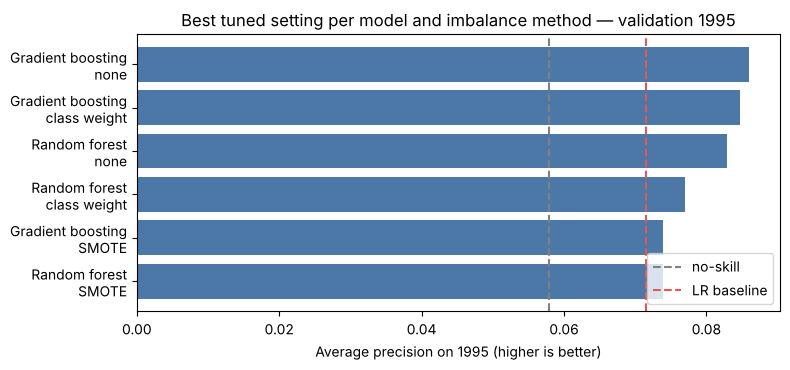

In [14]:
best_per_combo = (results.sort_values('AP', ascending=False)
                         .groupby(['model', 'imbalance'], as_index=False).first()
                         .sort_values('AP', ascending=False).reset_index(drop=True))
# Also show the MEDIAN AP across the grid: a method that only wins with one lucky setting is less trustworthy.
medians = results.groupby(['model', 'imbalance'])['AP'].median().rename('median AP over grid').reset_index()
best_per_combo = best_per_combo.merge(medians, on=['model', 'imbalance'])
display(best_per_combo[['model', 'imbalance', 'AP', 'median AP over grid', 'recall@10%', 'lift@10%', 'params']].round(4))

# Picture: best AP per combination vs the two reference lines
fig, ax = plt.subplots(figsize=(8, 3.8))
labels = best_per_combo['model'] + '\n' + best_per_combo['imbalance']
ax.barh(labels[::-1], best_per_combo['AP'][::-1], color='#4C78A8')
ax.axvline(reference.loc[0, 'AP'], color='gray', ls='--', label='no-skill')
ax.axvline(reference.loc[1, 'AP'], color='#E45756', ls='--', label='LR baseline')
ax.set_xlabel('Average precision on 1995 (higher is better)')
ax.set_title('Best tuned setting per model and imbalance method — validation 1995')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

## Step 13 — Is the winner *really* better, or did it get lucky?

1995 has only about 300 fraud cases, so a gap of 0.003 AP can be pure chance. A **bootstrap** checks this: re-draw 1995 (with replacement) 1,000 times,
re-score both models on each draw, and count how often the winner stays ahead. ~50% means "coin flip"; 90%+ means a fairly reliable lead.

We also compare the winner's 1994 (training) score to its 1995 score. A huge gap means it memorized 1994.

In [15]:
def refit_and_predict(row):
    X_tr, y_tr = TRAIN_SETS[row['imbalance']]
    m = make_model(row['model'], json.loads(row['params']), row['imbalance']).fit(X_tr, y_tr)
    return m, m.predict_proba(X_val)[:, 1]

winner = best_per_combo.iloc[0]
win_model, p_win = refit_and_predict(winner)
check(abs(average_precision_score(y_val, p_win) - winner['AP']) < 1e-9, 're-fitting the winner reproduces the same 1995 score (results are repeatable)')

def bootstrap_win_rate(p_a, p_b, n=1000):
    rng = np.random.default_rng(RANDOM_STATE)
    wins = 0
    for _ in range(n):
        idx = rng.integers(0, len(y_val), len(y_val))
        if y_val[idx].sum() == 0:
            continue
        wins += average_precision_score(y_val[idx], p_a[idx]) > average_precision_score(y_val[idx], p_b[idx])
    return wins / n

# Compare the winner against: the runner-up, the best of the OTHER imbalance methods for the same model, and the LR baseline
rivals = {'runner-up overall': best_per_combo.iloc[1]}
for imb in ['class weight', 'SMOTE', 'none']:
    if imb != winner['imbalance']:
        rivals[f"same model, {imb}"] = best_per_combo[(best_per_combo['model'] == winner['model']) &
                                                      (best_per_combo['imbalance'] == imb)].iloc[0]
boot_rows = []
for label, row in rivals.items():
    _, p_rival = refit_and_predict(row)
    boot_rows.append({'winner vs': f"{label}: {row['model']} + {row['imbalance']}", 'AP gap': winner['AP'] - row['AP'],
                      'winner ahead in % of resamples': 100 * bootstrap_win_rate(p_win, p_rival)})
boot_rows.append({'winner vs': 'LR baseline', 'AP gap': winner['AP'] - reference.loc[1, 'AP'],
                  'winner ahead in % of resamples': 100 * bootstrap_win_rate(p_win, lr.predict_proba(X_val)[:, 1])})
display(pd.DataFrame(boot_rows).round(4))

# --- Apply the tie-break rule from Step 7 ---
runner_up = best_per_combo.iloc[1]
lead_pct = boot_rows[0]['winner ahead in % of resamples']
if lead_pct < 75 and runner_up['recall@10%'] > winner['recall@10%']:
    chosen = runner_up
    print(f'\nTop two are a statistical tie (leader ahead in only {lead_pct:.0f}% of resamples).')
    print(f'Tie-break by recall@10%: {runner_up["recall@10%"]:.3f} vs {winner["recall@10%"]:.3f} -> choose the runner-up.')
else:
    chosen = winner
    print(f'\nKeeping the AP leader (ahead in {lead_pct:.0f}% of resamples, or it also has the better recall@10%).')
chosen_model, p_chosen = refit_and_predict(chosen)

# Overfitting check (on the REAL 1994 rows, even for a SMOTE model)
train_ap = average_precision_score(y_fit, chosen_model.predict_proba(X_fit)[:, 1])
print(f'\nCHOSEN: {chosen["model"]} + {chosen["imbalance"]}  {chosen["params"]}')
print(f'AP on 1994 (seen in training): {train_ap:.4f}   AP on 1995 (unseen): {chosen["AP"]:.4f}')
print('A big gap is normal for boosted trees on rare fraud; what matters is that 1995 beats the baseline and no-skill lines.')

  ✓ re-fitting the winner reproduces the same 1995 score (results are repeatable)


,winner vs,AP gap,winner ahead in % of resamples
0,runner-up overall: Gradient boosting + class w...,0.0012,59.4
1,"same model, class weight: Gradient boosting + ...",0.0012,59.4
2,"same model, SMOTE: Gradient boosting + SMOTE",0.0122,97.6
3,LR baseline,0.0146,99.6



Top two are a statistical tie (leader ahead in only 59% of resamples).
Tie-break by recall@10%: 0.163 vs 0.140 -> choose the runner-up.



CHOSEN: Gradient boosting + class weight  {"learning_rate": 0.1, "max_depth": 3, "min_samples_leaf": 50, "max_iter": 300}
AP on 1994 (seen in training): 0.4462   AP on 1995 (unseen): 0.0848
A big gap is normal for boosted trees on rare fraud; what matters is that 1995 beats the baseline and no-skill lines.


### Reading these results (1995 validation, fixed seed so they reproduce)

* **Class weighting vs SMOTE (the main question):** class weighting wins clearly for gradient boosting (AP 0.085 vs 0.074, ahead in ~98% of resamples) and for random forest (0.077 vs 0.074).
  SMOTE's fake fraud claims made both models *worse* at ranking real 1995 claims. Its top-10% lift for GB was ~1.0, no better than random.
* **Gradient boosting vs random forest:** GB is ahead under every imbalance method, and now RF had the same tuning effort, so this is a fair result.
* **Class weight vs no handling:** a tie on AP (0.085 vs 0.086, a coin flip in the bootstrap). That makes sense: AP only cares about the *order* of scores,
  and re-weighting mostly shifts scores up without reordering them much. The tie-break (recall@10%: 0.163 vs 0.140) picks **GB + class weight**.
* **Feature engineering:** the new features made no measurable difference (+0.0001 AP), so they're left out. That's still a result worth reporting.
* **Honest caveat:** best AP ≈ 0.085 against a 0.058 no-skill line is a modest lift (about 1.6× at the top 10%). The features on the claim form carry weak fraud signal,
  and 1995 has only 301 fraud cases, so differences under ~0.005 AP should be treated as noise.

## Step 14 — Review-budget view of the CHOSEN model (still 1995 only)

AP is one number. Investigators think in "how many claims can we open?" This table shows what the chosen model catches at different review rates on 1995.
When the team later opens 1996, they should pick **one** review rate from this table *before* looking at 1996 results.

In [16]:
budget = []
for frac in [0.05, 0.10, 0.20, 0.30]:
    rec, lift = top_k_stats(y_val, p_chosen, frac)
    k = int(len(p_chosen) * frac)
    budget.append({'review top': f'{frac:.0%}', 'claims reviewed': k,
                   'fraud caught': int(round(rec * y_val.sum())), 'of total fraud': int(y_val.sum()),
                   'recall': rec, 'lift vs random': lift})
display(pd.DataFrame(budget).round(3))

,review top,claims reviewed,fraud caught,of total fraud,recall,lift vs random
0,5%,259,29,301,0.096,1.932
1,10%,519,49,301,0.163,1.629
2,20%,1039,86,301,0.286,1.429
3,30%,1558,124,301,0.412,1.374


## Step 15 — Save the decision, prepare the final model, and prove 1996 was never used

We retrain the chosen recipe on **all of 1994–1995** (more data = a slightly better model) so it's ready for the one-time 1996 test later.
If the winner uses SMOTE, SMOTE is re-run on 1994–1995 only. Then we confirm the locked 1996 data was never changed or used.

In [17]:
# 1) Rebuild everything from 1994-95, learning the age median / columns / scaler from 1994-95 only.
dev_median = dev_df.loc[dev_df['Age'] > 0, 'Age'].median()
dev_clean = clean(dev_df, dev_median)
dev_train = smote_fit_year(dev_clean) if chosen['imbalance'] == 'SMOTE' else dev_clean
dev_train = add_features(dev_train) if USE_FE else dev_train
X_dev, _ = encode(dev_train, [], USE_FE)
num_cols = ['Age', 'Deductible'] + (ENGINEERED if USE_FE else [])
final_scaler = StandardScaler().fit(X_dev[num_cols])
X_dev[num_cols] = final_scaler.transform(X_dev[num_cols])
final_model = make_model(chosen['model'], json.loads(chosen['params']), chosen['imbalance']).fit(X_dev, dev_train[LABEL])

# 2) Write down the decision so the team can't "move the goalposts" after seeing 1996.
decision = {
    'chosen_model': chosen['model'], 'imbalance_method': chosen['imbalance'],
    'params': json.loads(chosen['params']), 'use_engineered_features': USE_FE,
    'validation_1995': {k: round(float(chosen[k]), 4) for k in ['AP', 'recall@10%', 'lift@10%']},
    'primary_metric': 'average precision', 'selected_on': 'fit 1994 / validate 1995',
    'test_1996_status': 'NOT YET EVALUATED',
}
with open('milestone2_model_choice.json', 'w') as fh:
    json.dump(decision, fh, indent=2)
print(json.dumps(decision, indent=2))

# 3) Proof that 1996 is untouched.
print()
check(int(pd.util.hash_pandas_object(holdout_1996, index=True).sum()) == HOLDOUT_FINGERPRINT, '1996 data is byte-for-byte unchanged')
check(set(dev_df.index).isdisjoint(holdout_1996.index), 'no 1996 claim is in the final training data')
check(len(X_dev) >= len(dev_df) and set(dev_clean['Year']) == {1994, 1995}, 'final model trained on 1994-95 only')

{
  "chosen_model": "Gradient boosting",
  "imbalance_method": "class weight",
  "params": {
    "learning_rate": 0.1,
    "max_depth": 3,
    "min_samples_leaf": 50,
    "max_iter": 300
  },
  "use_engineered_features": false,
  "validation_1995": {
    "AP": 0.0848,
    "recall@10%": 0.1628,
    "lift@10%": 1.6295
  },
  "primary_metric": "average precision",
  "selected_on": "fit 1994 / validate 1995",
  "test_1996_status": "NOT YET EVALUATED"
}

  ✓ 1996 data is byte-for-byte unchanged
  ✓ no 1996 claim is in the final training data
  ✓ final model trained on 1994-95 only


## What changed vs copy 2 / copy 3 (summary)

| Problem in old notebooks | Fixed here |
|---|---|
| 1996 test set was scored (copy 2 & 3), then used to compare models and flag rates | 1996 locked at Step 2, fingerprinted, never scored |
| Random forest never tuned; only GB got a grid search | Both models get a grid (Step 11) |
| SMOTE got one fixed setting; class weight got 36 | Every imbalance method gets the identical grid |
| No "no handling" reference | `none` included, so we can see if imbalance handling helps at all |
| SMOTENC treated `Deductible` as a number → fake values like 437 | `Deductible` treated as a category; checked |
| No feature engineering | Ordered ranges, claim delay, weekend filing; kept only if 1995 AP improves |
| Winner picked from tiny AP gaps with no uncertainty | Bootstrap win-rate + train-vs-validation overfitting check |

**Later, once (team decision):** load `milestone2_model_choice.json`, pick ONE review rate from Step 14, encode 1996 with the dev-fitted median/columns/scaler,
and score `final_model` on it exactly one time.